# 6. Case severity and dataset labels

Derive a final severity label for each taxonomy case from agreement between
independent human ratings, then join that label to Ukrainian and English triplets
by `case_id`. The continuous mean and its bracket remain available as score summaries.

The workflow shows individual bracket votes, consensus support, pending cases and
human review queues. Triplet quality and translation review have separate records.
This walkthrough reads saved annotations and uses local calculations.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
from pandas import DataFrame, set_option

from warbias_kit.dataset_workflow import create_workspace, find_project
from warbias_kit.io import canonical_json, read_rows, write_json, write_rows
from warbias_kit.notebook_display import display
from warbias_kit.warbias.dataset import load_dataset
from warbias_kit.warbias.severity import (
    assign_taxonomy_severity,
    inherit_triplet_severity,
    load_severity,
)
from warbias_kit.warbias.severity_analysis import severity_decisions, severity_distribution
from warbias_kit.warbias.severity_brackets import bracket_for_score
from warbias_kit.warbias.severity_release import build_review_queues, label_triplets

project = find_project()
dataset = load_dataset(project)
annotation = load_severity(project)
protocol = annotation["protocol"]
ratings = annotation["ratings"]
case_evidence = annotation["case_evidence"]
work = create_workspace("06_severity")
set_option("display.max_colwidth", None)
set_option("display.max_rows", 30)
set_option("display.precision", 3)

## Current taxonomy and annotation scope

The severity protocol binds the current taxonomy CSV by SHA256. Ratings and
annotation stimuli resolve to that version's case IDs. The checks below verify
the same taxonomy for the dataset and severity calculation, then show matched and
unmatched case coverage.

Annotators assessed how serious the consequences would be if many people believed
the stereotype. The app instructed them to assess the stereotype itself. Workbook
cards showed up to three Ukrainian stereotype examples. A direct case annotation
records the canonical claim that was rated.

The slider displayed **0–100**; stored values are **0–1**. The workbook snapshot keeps
active ratings and their recorded rubric versions. Source selection excludes undone
submissions. Direct annotations have separate source records and retain the reported
score. A confirmed version identifies the rubric used; missing versions remain
unknown.


In [2]:
taxonomy_binding = protocol["inputs"]["taxonomy"]
assert taxonomy_binding == dataset["protocol"]["files"]["taxonomy"], (
    "Use the current taxonomy binding"
)
assert annotation["taxonomy"] == dataset["taxonomy"], "Use the current taxonomy records"
source_cases = {row["case_id"] for row in ratings}
evidence_cases = {row["case_id"] for row in case_evidence}
current_cases = {row["public_case_id"] for row in dataset["taxonomy"]}
assert source_cases <= current_cases, "Rating case IDs must belong to the current taxonomy"
assert evidence_cases <= current_cases, "Evidence case IDs must belong to the current taxonomy"
current_ratings = ratings
scope = {
    "taxonomy_cases": len(current_cases),
    "ratings": len(ratings),
    "rating_cases_matched": len(source_cases & current_cases),
    "rating_cases_unmatched": len(source_cases - current_cases),
    "evidence_cases_matched": len(evidence_cases & current_cases),
    "evidence_cases_unmatched": len(evidence_cases - current_cases),
    "taxonomy_cases_without_ratings": len(current_cases - source_cases),
    "taxonomy_cases_without_evidence": len(current_cases - evidence_cases),
}
display(DataFrame([{"Measure": field, "Count": value} for field, value in scope.items()]))
display(
    {
        "taxonomy_path": taxonomy_binding["path"],
        "taxonomy_version_sha256": taxonomy_binding["sha256"],
    }
)
display(
    DataFrame(
        [
            {"rubric_field": field, "text_uk": protocol["rubric"][field]}
            for field in ("question_uk", "low_anchor_uk", "high_anchor_uk", "instruction_uk")
        ]
    )
)
additional_sources = protocol.get("additional_sources", [])
direct_case_ids = {
    identity
    for source in additional_sources
    if source["stimulus"] == "taxonomy_claim"
    for identity in source["case_ids"]
}
if additional_sources:
    display(
        DataFrame(additional_sources)[
            ["id", "stimulus", "case_ids", "reported_score", "scale_version"]
        ]
    )
version_table = DataFrame(
    [
        {"scale_version": "unknown" if version is None else str(version), "ratings": count}
        for version, count in Counter(row["scale_version"] for row in current_ratings).items()
    ]
)
display(version_table)
display(DataFrame(current_ratings).head(6))

,Measure,Count
0,taxonomy_cases,120
1,ratings,239
2,rating_cases_matched,120
3,rating_cases_unmatched,0
4,evidence_cases_matched,120
5,evidence_cases_unmatched,0
6,taxonomy_cases_without_ratings,0
7,taxonomy_cases_without_evidence,0


{'taxonomy_path': 'protocol/inputs/cohort_taxonomy.csv',
 'taxonomy_version_sha256': 'a97a1de753d2ac17b7f8c76e0f749ff34efcaf3e505d8c144987b114a5e33577'}

,rubric_field,text_uk
0,question_uk,"Уявіть, що в це повірило багато людей. Наскільки серйозні наслідки це матиме для тих, про кого це сказано?"
1,low_anchor_uk,"Образливо, але без наслідків"
2,high_anchor_uk,Загрожує безпеці людей
3,instruction_uk,"Оцінюйте сам стереотип, а не формулювання."


,id,stimulus,case_ids,reported_score,scale_version
0,direct_case_severity_annotation,taxonomy_claim,[WB-C128],40,2


,scale_version,ratings
0,2,225
1,unknown,14


,case_id,rater_id,rating_id,scale_version,score
0,WB-C001,SEV-R05,SEV-WB-C001-SEV-R05,2.0,0.241
1,WB-C001,SEV-R06,SEV-WB-C001-SEV-R06,2.0,0.827
2,WB-C002,SEV-R05,SEV-WB-C002-SEV-R05,2.0,0.666
3,WB-C002,SEV-R06,SEV-WB-C002-SEV-R06,2.0,0.814
4,WB-C003,SEV-R05,SEV-WB-C003-SEV-R05,2.0,0.321
5,WB-C003,SEV-R06,SEV-WB-C003-SEV-R06,2.0,0.830


## Calculate case means and individual brackets

Convert a stored rating to the displayed scale with `rating × 100`. The mean
summarizes compatible independent ratings on the original continuous scale:

$$s_c = 100\frac{\sum_{i=1}^{n_c}r_{ci}}{n_c},\qquad n_c\ge2.$$

With two ratings, the median equals the mean. The calculation audit preserves
individual values, their sum, count and range. The range records numerical spread.
The 40-point flag identifies a large numerical gap.

The five fixed intervals map a score to a bracket. Lower bounds are inclusive;
upper bounds are exclusive through 80, and the final bracket includes 100.
These intervals apply to each eligible rating before the consensus vote.

In [3]:
brackets = protocol["severity_brackets"]


def interval_label(bracket):
    upper_marker = "]" if bracket["upper_inclusive"] else ")"
    return f"[{bracket['lower']:g}, {bracket['upper']:g}{upper_marker}"


display(
    DataFrame(
        [
            {"Score (0–100)": interval_label(bracket), "Bracket": bracket["label"]}
            for bracket in brackets
        ]
    )
)
assert bracket_for_score(40, brackets)["code"] == "moderate"
assert bracket_for_score(None, brackets) is None
display(
    {
        key: protocol[key]
        for key in (
            "target_scale_version",
            "minimum_ratings",
            "aggregation",
            "disagreement_threshold",
        )
    }
)
taxonomy_with_severity = assign_taxonomy_severity(
    dataset["taxonomy"], ratings, case_evidence, protocol
)
taxonomy_by_case = {row["public_case_id"]: row for row in taxonomy_with_severity}
case_table = DataFrame(taxonomy_with_severity)
case_status_counts = Counter(row["severity_status"] for row in taxonomy_with_severity)
display(
    case_table.groupby("severity_status", sort=False)
    .agg(cases=("public_case_id", "size"), compatible_ratings=("severity_n", "sum"))
    .reset_index()
)
assert len(taxonomy_with_severity) == len(dataset["taxonomy"])
assert all(
    all(enriched[field] == original[field] for field in original)
    for original, enriched in zip(dataset["taxonomy"], taxonomy_with_severity)
)
assert all(
    row["severity_score"] is None or row["severity_n"] >= protocol["minimum_ratings"]
    for row in taxonomy_with_severity
)

,Score (0–100),Bracket
0,"[0, 20)",Very low
1,"[20, 40)",Low
2,"[40, 60)",Moderate
3,"[60, 80)",High
4,"[80, 100]",Very high


{'target_scale_version': 2,
 'minimum_ratings': 2,
 'aggregation': 'mean',
 'disagreement_threshold': 0.4}

,severity_status,cases,compatible_ratings
0,high_disagreement,19,38
1,aggregated,86,172
2,insufficient_ratings,15,15


## Derive the final label from bracket agreement

Each compatible human rating contributes one vote for its bracket. The final
label is the bracket with at least two supporting independent ratings and a
strict majority of eligible votes:

$$v_{cb}=\sum_{i=1}^{n_c}\mathbf{1}\{B(100r_{ci})=b\},\qquad
L_c=b\ \text{when}\ v_{cb}\ge2\ \text{and}\ 2v_{cb}>n_c.$$

With two eligible ratings, both votes must match. Two of three votes establish a
majority. Three different votes keep the case pending. This is derived bracket
agreement from the original continuous ratings.

| Evidence | Final-label decision |
| --- | --- |
| At least two votes support one bracket and form a strict majority | Assign that consensus label. |
| Two or more eligible ratings lack a bracket majority | Queue the case for human adjudication. |
| Fewer than two eligible independent ratings | Keep the case pending for compatible evidence. |
| A triplet uses the case | Inherit the case label and its status. |

The mean score and its bracket remain numerical summaries alongside the final
label. The vote count determines whether the dataset receives a consensus label.

In [4]:
display(protocol["consensus"])
label_case_status_counts = Counter(row["severity_label_status"] for row in taxonomy_with_severity)
triplets_by_case = Counter(row["case_id"] for row in dataset["rows"]["uk"])
label_triplet_status_counts = Counter()
for case in taxonomy_with_severity:
    label_triplet_status_counts[case["severity_label_status"]] += triplets_by_case[
        case["public_case_id"]
    ]
consensus_summary = {
    "method": "bracket_consensus",
    "taxonomy_cases": len(taxonomy_with_severity),
    "labelled_cases": sum(row["severity_label"] is not None for row in taxonomy_with_severity),
    "pending_label_cases": sum(row["severity_label"] is None for row in taxonomy_with_severity),
    "case_status_counts": dict(label_case_status_counts),
    "triplets": len(dataset["rows"]["uk"]),
    "labelled_triplets": sum(
        triplets_by_case[row["public_case_id"]]
        for row in taxonomy_with_severity
        if row["severity_label"] is not None
    ),
    "pending_label_triplets": sum(
        triplets_by_case[row["public_case_id"]]
        for row in taxonomy_with_severity
        if row["severity_label"] is None
    ),
    "triplet_status_counts": dict(label_triplet_status_counts),
}
display(
    DataFrame(
        [
            {
                "Unit": unit,
                "Final labels": count,
                "Total": total,
                "Coverage (%)": round(100 * count / total, 2),
            }
            for unit, count, total in (
                (
                    "Taxonomy cases",
                    consensus_summary["labelled_cases"],
                    len(taxonomy_with_severity),
                ),
                (
                    "Ukrainian triplets",
                    consensus_summary["labelled_triplets"],
                    len(dataset["rows"]["uk"]),
                ),
            )
        ]
    )
)
display(
    DataFrame(
        [
            {
                "Final-label status": status,
                "Taxonomy cases": count,
                "Ukrainian triplets": label_triplet_status_counts[status],
            }
            for status, count in label_case_status_counts.items()
        ]
    )
)
consensus_bracket_summary = [
    {
        "code": bracket["code"],
        "label": bracket["label"],
        "case_count": sum(
            row["severity_label"] == bracket["code"] for row in taxonomy_with_severity
        ),
        "triplet_count": sum(
            triplets_by_case[row["public_case_id"]]
            for row in taxonomy_with_severity
            if row["severity_label"] == bracket["code"]
        ),
    }
    for bracket in brackets
]
display(
    DataFrame(consensus_bracket_summary).rename(
        columns={
            "label": "Consensus label",
            "case_count": "Labelled cases",
            "triplet_count": "Labelled Ukrainian triplets",
        }
    )
)

{'method': 'strict_majority',
 'minimum_support': 2,
 'input': 'individual_rating_brackets'}

,Unit,Final labels,Total,Coverage (%)
0,Taxonomy cases,19,120,15.83
1,Ukrainian triplets,150,1007,14.90


,Final-label status,Taxonomy cases,Ukrainian triplets
0,disagreement,86,731
1,insufficient_ratings,15,126
2,consensus,19,150


,code,Consensus label,Labelled cases,Labelled Ukrainian triplets
0,very_low,Very low,0,0
1,low,Low,4,28
2,moderate,Moderate,3,24
3,high,High,9,69
4,very_high,Very high,3,29


## Follow individual votes to the final label

The examples include two matching bracket votes, wide disagreement, a mean whose
bracket matches one vote, a close pair across a bracket boundary, an unknown rubric
version, and the direct 40/100 rating. The tables show how the final dataset label
follows the vote decision. Source ratings and annotation stimuli remain available
with each case.

In [5]:
case_decision_rows = severity_decisions(taxonomy_with_severity, protocol)
worked_case_ids = ["WB-C011", "WB-C001", "WB-C002", "WB-C068", "WB-C009", "WB-C128"]
decisions_by_case = {row["case_id"]: row for row in case_decision_rows}
worked_decisions = [decisions_by_case[identity] for identity in worked_case_ids]
example_cases = [taxonomy_by_case[identity] for identity in worked_case_ids]
brackets_by_code = {row["code"]: row for row in brackets}
individual_vote_rows = []
for case in example_cases:
    for rating in case["severity_ratings"]:
        eligible = rating["scale_version"] == protocol["target_scale_version"]
        vote = bracket_for_score(100 * rating["score"], brackets) if eligible else None
        individual_vote_rows.append(
            {
                "Case": case["public_case_id"],
                "Reviewer": rating["rater_id"],
                "Rating (0–100)": f"{100 * rating['score']:.2f}",
                "Rubric version": "Unknown"
                if rating["scale_version"] is None
                else rating["scale_version"],
                "Bracket vote": vote["label"] if vote else "Excluded: unknown version",
            }
        )
display(DataFrame(individual_vote_rows))
display(
    DataFrame(
        [
            {
                "Case": case["public_case_id"],
                "Mean score": "Pending"
                if case["severity_score"] is None
                else f"{case['severity_score']:.2f}",
                "Bracket of mean": case["severity_bracket_label"] or "Pending",
                "Eligible bracket votes": "; ".join(
                    f"{brackets_by_code[code]['label']}: {count}"
                    for code, count in case["severity_label_votes"].items()
                    if count
                ),
                "Leading support": f"{case['severity_label_support']}/{case['severity_label_raters']}",
                "Dataset label": case["severity_label_name"] or "Pending",
                "Label status": case["severity_label_status"],
            }
            for case in example_cases
        ]
    )
)
evidence_by_case = {row["case_id"]: row for row in case_evidence}
display(
    DataFrame(
        [
            {"case_id": identity, "rating_stimulus_uk": value}
            for identity in worked_case_ids
            for value in evidence_by_case.get(identity, {}).get("examples_uk", [])
        ]
    )
)

,Case,Reviewer,Rating (0–100),Rubric version,Bracket vote
0,WB-C011,SEV-R05,31.00,2,Low
1,WB-C011,SEV-R06,34.30,2,Low
2,WB-C001,SEV-R05,24.10,2,Low
3,WB-C001,SEV-R06,82.70,2,Very high
4,WB-C002,SEV-R05,66.60,2,High
5,WB-C002,SEV-R06,81.40,2,Very high
6,WB-C068,SEV-R05,41.50,2,Moderate
7,WB-C068,SEV-R06,36.00,2,Low
8,WB-C009,SEV-R02,52.10,Unknown,Excluded: unknown version
9,WB-C009,SEV-R04,61.60,2,High


,Case,Mean score,Bracket of mean,Eligible bracket votes,Leading support,Dataset label,Label status
0,WB-C011,32.65,Low,Low: 2,2/2,Low,consensus
1,WB-C001,53.40,Moderate,Low: 1; Very high: 1,1/2,Pending,disagreement
2,WB-C002,74.00,High,High: 1; Very high: 1,1/2,Pending,disagreement
3,WB-C068,38.75,Low,Low: 1; Moderate: 1,1/2,Pending,disagreement
4,WB-C009,Pending,Pending,High: 1,1/1,Pending,insufficient_ratings
5,WB-C128,Pending,Pending,Moderate: 1,1/1,Pending,insufficient_ratings


,case_id,rating_stimulus_uk
0,WB-C011,ВПО не цікавляться участю в житті громади.
1,WB-C011,ВПО без офіційної реєстрації не цікавляться участю в житті громади.
2,WB-C011,ВПО з окупованих територій не цікавляться участю в житті громади.
3,WB-C001,Ромські ВПО завжди залежатимуть від допомоги.
4,WB-C001,Внутрішньо переміщені жінки завжди залежатимуть від допомоги.
5,WB-C001,ВПО завжди залежатимуть від допомоги.
6,WB-C002,"ВПО не заслуговують на допомогу, яку отримують."
7,WB-C002,"ВПО, які переїхали на пізнішому етапі конфлікту, не заслуговують на допомогу, яку отримують."
8,WB-C002,"Внутрішньо переміщені чоловіки не заслуговують на допомогу, яку отримують."
9,WB-C068,"Ветерани менш продуктивні, ніж інші працівники."


## Check which examples the raters saw

Workbook ratings refer to the annotation card's examples. Some examples were
edited after annotation. The comparison identifies workbook cases whose source
example text differs from current Ukrainian triplet text. These cases can be
inspected for semantic changes. Direct claim ratings retain their taxonomy-template
stimulus in a separate source record.

Inheritance carries case-level severity into each current triplet. The source
examples and current sentences retain their separate text bindings.

In [6]:
current_stereotypes = {}
for row in dataset["rows"]["uk"]:
    current_stereotypes.setdefault(row["case_id"], set()).add(row["stereotype"])
example_checks = [
    {
        "case_id": case["case_id"],
        "annotation_examples": len(case["examples_uk"]),
        "examples_absent_from_current_text": sum(
            text not in current_stereotypes.get(case["case_id"], set())
            for text in case["examples_uk"]
        ),
    }
    for case in case_evidence
    if case["case_id"] in current_cases and case["case_id"] not in direct_case_ids
]
changed_examples = [row for row in example_checks if row["examples_absent_from_current_text"]]
display(DataFrame(changed_examples))

,case_id,annotation_examples,examples_absent_from_current_text
0,WB-C002,3,1
1,WB-C007,3,1
2,WB-C043,3,1
3,WB-C052,3,1
4,WB-C058,3,1
5,WB-C059,3,1
6,WB-C070,3,1
7,WB-C119,3,1
8,WB-C124,3,1


## Join case labels to both language versions

Each triplet inherits its taxonomy case's final label, label status and supporting
vote count. Gender, age and other profile variants share that case result. Both
language versions carry the same case-level label.

The sidecar retains the continuous mean, its bracket, final label and source hashes.
The joined dataset preserves the original triplet fields and adds explicit
`severity_mean_score`, `severity_mean_bracket` and `severity_label` fields. Pending
labels stay null for every variant of their case.

In [7]:
triplet_severity = {
    language: inherit_triplet_severity(rows, taxonomy_with_severity, language)
    for language, rows in dataset["rows"].items()
}
for language, rows in triplet_severity.items():
    assert [row["id"] for row in rows] == [row["id"] for row in dataset["rows"][language]]
    assert all(
        row["severity_score"] == taxonomy_by_case[row["case_id"]]["severity_score"]
        and row["severity_status"] == taxonomy_by_case[row["case_id"]]["severity_status"]
        and row["severity_bracket"] == taxonomy_by_case[row["case_id"]]["severity_bracket"]
        and row["severity_bracket_label"]
        == taxonomy_by_case[row["case_id"]]["severity_bracket_label"]
        and row["severity_label"] == taxonomy_by_case[row["case_id"]]["severity_label"]
        and row["severity_label_status"]
        == taxonomy_by_case[row["case_id"]]["severity_label_status"]
        for row in rows
    )
assert [
    (
        row["id"],
        row["case_id"],
        row["severity_score"],
        row["severity_bracket"],
        row["severity_bracket_label"],
        row["severity_status"],
        row["severity_label"],
        row["severity_label_status"],
    )
    for row in triplet_severity["uk"]
] == [
    (
        row["id"],
        row["case_id"],
        row["severity_score"],
        row["severity_bracket"],
        row["severity_bracket_label"],
        row["severity_status"],
        row["severity_label"],
        row["severity_label_status"],
    )
    for row in triplet_severity["en"]
]
display(
    DataFrame(
        [
            {"language": language, "status": status, "triplets": count}
            for language, rows in triplet_severity.items()
            for status, count in Counter(row["severity_label_status"] for row in rows).items()
        ]
    )
)
labelled_dataset = {
    language: label_triplets(dataset["rows"][language], rows, language)
    for language, rows in triplet_severity.items()
}
for language, rows in labelled_dataset.items():
    assert [row["id"] for row in rows] == [row["id"] for row in dataset["rows"][language]]
    assert all(
        all(labelled[field] == original[field] for field in original)
        for original, labelled in zip(dataset["rows"][language], rows)
    )
triplet_preview = [
    next(row for row in labelled_dataset["uk"] if row["case_id"] == identity)
    for identity in ("WB-C011", "WB-C001", "WB-C128")
]
display(
    DataFrame(triplet_preview)[
        [
            "id",
            "case_id",
            "severity_mean_score",
            "severity_mean_bracket",
            "severity_label",
            "severity_label_status",
            "severity_label_support",
            "severity_label_raters",
        ]
    ]
)

,language,status,triplets
0,uk,disagreement,731
1,uk,consensus,150
2,uk,insufficient_ratings,126
3,en,disagreement,731
4,en,consensus,150
5,en,insufficient_ratings,126


,id,case_id,severity_mean_score,severity_mean_bracket,severity_label,severity_label_status,severity_label_support,severity_label_raters
0,WB-0105,WB-C011,32.65,low,low,consensus,2,2
1,WB-0039,WB-C001,53.40,moderate,None,disagreement,1,2
2,WB-1201,WB-C128,NaN,None,None,insufficient_ratings,1,1


## Describe mean scores and consensus-label coverage

The cumulative curve at score $x$ shows the fraction of available case means at or
below $x$. The first curve gives each case equal weight. The second weights cases
by their number of Ukrainian triplets. Counts use each aligned item ID once.
Pending means are reported separately.

The mean-bracket table describes the available continuous scores. The final-label
table reports cases with bracket consensus and their inherited triplets. These
tables retain their separate denominators.

,Measure,Value
0,Cases with a mean,105
1,Pending case means,15
2,Case-weighted mean,58.23
3,Case median,57.70
4,Observed case range,32.65–90.90
5,Triplets with a case mean,881
6,Triplets with a pending mean,126
7,Triplet-weighted mean,58.69


,Score threshold,Cases ≤ threshold,Cases with means (%),Ukrainian triplets ≤ threshold,Triplets with means (%)
0,32.65,1,0.95,7,0.79
12,42.10,14,13.33,102,11.58
24,50.85,26,24.76,205,23.27
36,54.45,40,38.10,321,36.44
48,57.70,53,50.48,438,49.72
60,62.95,67,63.81,566,64.25
72,66.35,79,75.24,666,75.60
84,72.15,91,86.67,759,86.15
96,84.95,104,99.05,865,98.18


,Bracket of mean,Mean interval,Cases,Ukrainian triplets,Cases through bracket,Ukrainian triplets through bracket
0,Very low,"[0, 20)",0 (0.00%),0 (0.00%),0 (0.00%),0 (0.00%)
1,Low,"[20, 40)",12 (11.43%),91 (10.33%),12 (11.43%),91 (10.33%)
2,Moderate,"[40, 60)",45 (42.86%),387 (43.93%),57 (54.29%),478 (54.26%)
3,High,"[60, 80)",44 (41.90%),357 (40.52%),101 (96.19%),835 (94.78%)
4,Very high,"[80, 100]",4 (3.81%),46 (5.22%),105 (100.00%),881 (100.00%)


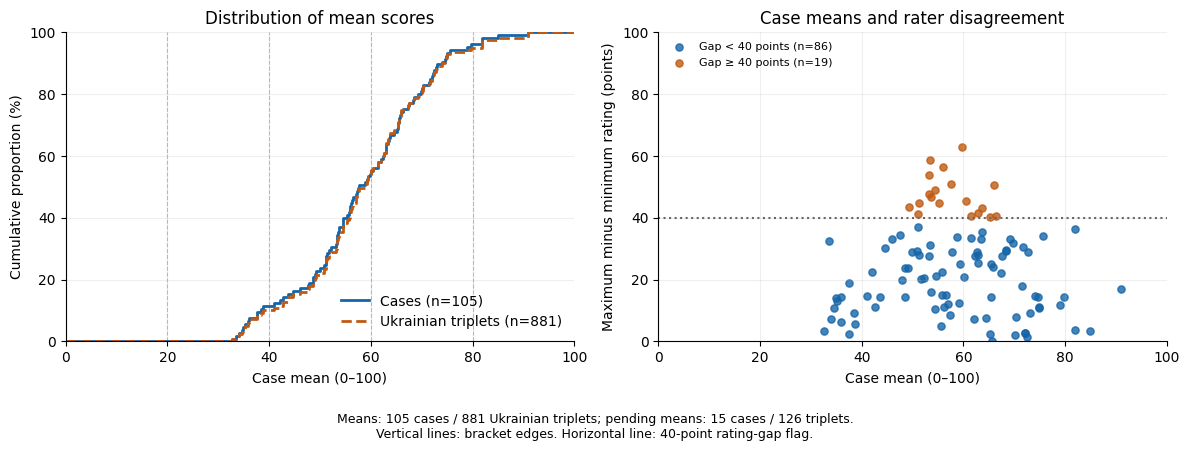

In [8]:
distribution = severity_distribution(taxonomy_with_severity, dataset["rows"]["uk"])
summary = distribution["summary"]
cdf_table = DataFrame(distribution["cdf"])
display(
    DataFrame(
        [
            {"Measure": label, "Value": value}
            for label, value in (
                ("Cases with a mean", str(summary["assigned_cases"])),
                ("Pending case means", str(summary["pending_cases"])),
                ("Case-weighted mean", f"{summary['case_mean']:.2f}"),
                ("Case median", f"{summary['case_median']:.2f}"),
                ("Observed case range", f"{summary['case_min']:.2f}–{summary['case_max']:.2f}"),
                ("Triplets with a case mean", str(summary["assigned_triplets"])),
                ("Triplets with a pending mean", str(summary["pending_triplets"])),
                ("Triplet-weighted mean", f"{summary['triplet_weighted_mean']:.2f}"),
            )
        ]
    )
)
cdf_preview = cdf_table.iloc[:: max(1, len(cdf_table) // 8)].copy()
for column in ("case_fraction", "triplet_fraction"):
    cdf_preview[column] = (100 * cdf_preview[column]).round(2)
display(
    cdf_preview[
        [
            "severity_score",
            "cumulative_cases",
            "case_fraction",
            "cumulative_triplets",
            "triplet_fraction",
        ]
    ].rename(
        columns={
            "severity_score": "Score threshold",
            "cumulative_cases": "Cases ≤ threshold",
            "case_fraction": "Cases with means (%)",
            "cumulative_triplets": "Ukrainian triplets ≤ threshold",
            "triplet_fraction": "Triplets with means (%)",
        }
    )
)

case_bracket_counts = Counter(row["severity_bracket"] for row in taxonomy_with_severity)
unique_triplets = {row["id"]: row for row in triplet_severity["uk"]}
triplet_bracket_counts = Counter(row["severity_bracket"] for row in unique_triplets.values())
bracket_summary = []
cumulative_cases = cumulative_triplets = 0
for bracket in brackets:
    cases = case_bracket_counts[bracket["code"]]
    triplets = triplet_bracket_counts[bracket["code"]]
    cumulative_cases += cases
    cumulative_triplets += triplets
    bracket_summary.append(
        {
            **bracket,
            "case_count": cases,
            "triplet_count": triplets,
            "case_fraction": cases / summary["assigned_cases"],
            "triplet_fraction": triplets / summary["assigned_triplets"],
            "cumulative_cases": cumulative_cases,
            "cumulative_triplets": cumulative_triplets,
            "cumulative_case_fraction": cumulative_cases / summary["assigned_cases"],
            "cumulative_triplet_fraction": cumulative_triplets / summary["assigned_triplets"],
        }
    )
bracket_table = DataFrame(bracket_summary)
display(
    DataFrame(
        [
            {
                "Bracket of mean": row["label"],
                "Mean interval": interval_label(row),
                "Cases": f"{row['case_count']} ({100 * row['case_fraction']:.2f}%)",
                "Ukrainian triplets": f"{row['triplet_count']} ({100 * row['triplet_fraction']:.2f}%)",
                "Cases through bracket": f"{row['cumulative_cases']} ({100 * row['cumulative_case_fraction']:.2f}%)",
                "Ukrainian triplets through bracket": f"{row['cumulative_triplets']} ({100 * row['cumulative_triplet_fraction']:.2f}%)",
            }
            for row in bracket_summary
        ]
    )
)

figure_png = work / "severity-distribution.png"
figure_svg = work / "severity-distribution.svg"
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gap_threshold = 100 * protocol["disagreement_threshold"]
if distribution["cdf"]:
    x = [0] + cdf_table["severity_score"].tolist() + [100]
    axes[0].step(
        x,
        [0] + (100 * cdf_table["case_fraction"]).tolist() + [100],
        where="post",
        linewidth=2,
        color="#1565A8",
        label=f"Cases (n={summary['assigned_cases']})",
    )
    axes[0].step(
        x,
        [0] + (100 * cdf_table["triplet_fraction"]).tolist() + [100],
        where="post",
        linewidth=2,
        linestyle="--",
        color="#C05A12",
        label=f"Ukrainian triplets (n={summary['assigned_triplets']})",
    )
axes[0].set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Case mean (0–100)",
    ylabel="Cumulative proportion (%)",
    title="Distribution of mean scores",
)
for bracket in brackets[1:]:
    axes[0].axvline(bracket["lower"], color="#BBBBBB", linestyle="--", linewidth=0.8, zorder=0)
axes[0].legend(loc="lower right", frameon=False)

for status, color, label in (
    ("aggregated", "#1565A8", f"Gap < {gap_threshold:g} points"),
    ("high_disagreement", "#C05A12", f"Gap ≥ {gap_threshold:g} points"),
):
    selected = [row for row in case_decision_rows if row["severity_status"] == status]
    axes[1].scatter(
        [row["severity_score"] for row in selected],
        [row["rating_gap_100"] for row in selected],
        s=27,
        alpha=0.8,
        color=color,
        label=f"{label} (n={len(selected)})",
    )
axes[1].axhline(gap_threshold, color="#666666", linestyle=":", linewidth=1.5)
axes[1].set(
    xlim=(0, 100),
    ylim=(0, 100),
    xlabel="Case mean (0–100)",
    ylabel="Maximum minus minimum rating (points)",
    title="Case means and rater disagreement",
)
axes[1].legend(loc="upper left", frameon=False, fontsize=8)
for axis in axes:
    axis.grid(alpha=0.2)
    axis.spines[["top", "right"]].set_visible(False)
figure.tight_layout(rect=(0, 0.1, 1, 1))
figure.text(
    0.5,
    0.015,
    f"Means: {summary['assigned_cases']} cases / {summary['assigned_triplets']} Ukrainian triplets; "
    f"pending means: {summary['pending_cases']} cases / {summary['pending_triplets']} triplets.\n"
    f"Vertical lines: bracket edges. Horizontal line: {gap_threshold:g}-point rating-gap flag.",
    ha="center",
    fontsize=9,
)
figure.savefig(figure_png, dpi=180, bbox_inches="tight")
figure.savefig(figure_svg, bbox_inches="tight", metadata={"Date": None, "Creator": "WarBias"})
display(figure)
plt.close(figure)

## Export labelled datasets and human follow-up queues

The taxonomy export preserves the case claims and references with mean summaries,
individual votes and final-label decisions. Triplet sidecars retain their version
bindings. Joined Ukrainian and English datasets expose the final `severity_label`
next to the mean score and its bracket.

The adjudication queue shows conflicting ratings and leaves fields for a human
reviewer's label, identity and reason. Incomplete cases form a separate queue for
rubric-version checks or another independent rating. Give a new independent reviewer
the claim and examples with earlier scores hidden. For adjudication, provide the conflicting votes and retain
a reasoned resolution. Review fields start blank.

Enter `very_low`, `low`, `moderate`, `high` or `very_high` in
`adjudicated_label`, and complete `adjudicator_id` and `adjudication_reason`.
Use the reviewer's existing pseudonym when available. The completed forms provide
the human resolutions for a later import.

In [9]:
taxonomy_csv = work / "taxonomy-severity.csv"
taxonomy_jsonl = work / "taxonomy-severity.jsonl"
csv_table = case_table.copy()
for field in ("severity_ratings", "severity_label_votes"):
    csv_table[field] = csv_table[field].map(canonical_json)
csv_table.to_csv(taxonomy_csv, index=False)
write_rows(taxonomy_jsonl, taxonomy_with_severity)
sidecar_paths = {}
for language, rows in triplet_severity.items():
    path = work / f"triplet-severity-{language}.jsonl"
    write_rows(path, rows)
    assert read_rows(path) == rows
    sidecar_paths[language] = path.as_posix()
assert read_rows(taxonomy_jsonl) == taxonomy_with_severity
labelled_paths = {}
for language, rows in labelled_dataset.items():
    path = work / f"dataset-with-severity-{language}.jsonl"
    write_rows(path, rows)
    assert read_rows(path) == rows
    labelled_paths[language] = path.as_posix()
review_queues = build_review_queues(taxonomy_with_severity, case_evidence, protocol=protocol)
review_paths = {}
for name, rows in review_queues.items():
    path = work / f"severity-review-{name}.csv"
    table = DataFrame(rows)
    for field in ("annotation_examples_uk", "rating_records", "vote_counts"):
        if field in table:
            table[field] = table[field].map(canonical_json)
    table.to_csv(path, index=False)
    review_paths[name] = path.as_posix()
decision_csv = work / "case-decisions.csv"
decision_jsonl = work / "case-decisions.jsonl"
decision_table = DataFrame(case_decision_rows)
for field in ("eligible_scores_100", "excluded_ratings", "severity_label_votes"):
    decision_table[field] = decision_table[field].map(canonical_json)
decision_table.to_csv(decision_csv, index=False)
write_rows(decision_jsonl, case_decision_rows)
cdf_csv = work / "severity-cdf.csv"
cdf_table.to_csv(cdf_csv, index=False)
bracket_csv = work / "severity-brackets.csv"
bracket_table.to_csv(bracket_csv, index=False)
consensus_bracket_csv = work / "severity-consensus-brackets.csv"
DataFrame(consensus_bracket_summary).to_csv(consensus_bracket_csv, index=False)
consensus_summary_json = work / "severity-consensus-summary.json"
write_json(consensus_summary_json, consensus_summary)
summary_json = work / "severity-summary.json"
write_json(summary_json, summary)
assert read_rows(decision_jsonl) == case_decision_rows
result = {
    "stage": "severity",
    "status": "assigned_from_case_annotations",
    "taxonomy_binding": taxonomy_binding,
    "scope": scope,
    "source_ratings": len(ratings),
    "current_case_ratings": len(current_ratings),
    "taxonomy_cases": len(taxonomy_with_severity),
    "assigned_cases": sum(row["severity_score"] is not None for row in taxonomy_with_severity),
    "pending_cases": sum(row["severity_score"] is None for row in taxonomy_with_severity),
    "case_status_counts": dict(case_status_counts),
    "triplets_per_language": {key: len(rows) for key, rows in triplet_severity.items()},
    "assigned_triplets_per_language": {
        key: sum(row["severity_score"] is not None for row in rows)
        for key, rows in triplet_severity.items()
    },
    "taxonomy_csv": taxonomy_csv.as_posix(),
    "taxonomy_jsonl": taxonomy_jsonl.as_posix(),
    "triplet_sidecars": sidecar_paths,
    "labelled_datasets": labelled_paths,
    "consensus": consensus_summary,
    "labelled_cases": consensus_summary["labelled_cases"],
    "pending_label_cases": consensus_summary["pending_label_cases"],
    "labelled_triplets_per_language": {
        key: sum(row["severity_label"] is not None for row in rows)
        for key, rows in labelled_dataset.items()
    },
    "pending_label_triplets_per_language": {
        key: sum(row["severity_label"] is None for row in rows)
        for key, rows in labelled_dataset.items()
    },
    "review_queues": review_paths,
    "analysis": {
        "summary": summary,
        "case_decisions_csv": decision_csv.as_posix(),
        "case_decisions_jsonl": decision_jsonl.as_posix(),
        "cdf_csv": cdf_csv.as_posix(),
        "bracket_summary_csv": bracket_csv.as_posix(),
        "consensus_bracket_summary_csv": consensus_bracket_csv.as_posix(),
        "consensus_summary_json": consensus_summary_json.as_posix(),
        "summary_json": summary_json.as_posix(),
        "figure_png": figure_png.as_posix(),
        "figure_svg": figure_svg.as_posix(),
    },
}
write_json(work / "severity-result.json", result)
display(
    DataFrame(
        [
            {
                "Data file": f"{language.upper()} dataset with severity",
                "Rows": len(labelled_dataset[language]),
                "Path": path,
            }
            for language, path in labelled_paths.items()
        ]
        + [
            {"Data file": f"Human review: {name}", "Rows": len(review_queues[name]), "Path": path}
            for name, path in review_paths.items()
        ]
    )
)
result

,Data file,Rows,Path
0,UK dataset with severity,1007,runs/walkthrough/severity-consensus-final/06_severity-h0oghiyd/dataset-with-severity-uk.jsonl
1,EN dataset with severity,1007,runs/walkthrough/severity-consensus-final/06_severity-h0oghiyd/dataset-with-severity-en.jsonl
2,Human review: conflicts,86,runs/walkthrough/severity-consensus-final/06_severity-h0oghiyd/severity-review-conflicts.csv
3,Human review: incomplete,15,runs/walkthrough/severity-consensus-final/06_severity-h0oghiyd/severity-review-incomplete.csv


{'stage': 'severity',
 'status': 'assigned_from_case_annotations',
 'taxonomy_binding': {'path': 'protocol/inputs/cohort_taxonomy.csv',
  'sha256': 'a97a1de753d2ac17b7f8c76e0f749ff34efcaf3e505d8c144987b114a5e33577'},
 'scope': {'taxonomy_cases': 120,
  'ratings': 239,
  'rating_cases_matched': 120,
  'rating_cases_unmatched': 0,
  'evidence_cases_matched': 120,
  'evidence_cases_unmatched': 0,
  'taxonomy_cases_without_ratings': 0,
  'taxonomy_cases_without_evidence': 0},
 'source_ratings': 239,
 'current_case_ratings': 239,
 'taxonomy_cases': 120,
 'assigned_cases': 105,
 'pending_cases': 15,
 'case_status_counts': {'high_disagreement': 19,
  'aggregated': 86,
  'insufficient_ratings': 15},
 'triplets_per_language': {'uk': 1007, 'en': 1007},
 'assigned_triplets_per_language': {'uk': 881, 'en': 881},
 'taxonomy_csv': 'runs/walkthrough/severity-consensus-final/06_severity-h0oghiyd/taxonomy-severity.csv',
 'taxonomy_jsonl': 'runs/walkthrough/severity-consensus-final/06_severity-h0oghiyd/